# OrbitShop — Due Diligence Series C (Análise Executiva Auditável)
**Case Técnico: Peers Consulting & Technology**

---

## 0. Sumário Executivo & Configuração da Arquitetura Modular

Este notebook apresenta o diagnóstico executivo ponta a ponta da **OrbitShop** (operação de e-commerce 2023–2024) para subsidiar o Comitê de Investimentos Series C. Toda a lógica de ingestão, auditoria de integridade, reconciliação financeira, cálculo de indicadores e geração de visualizações reside nos módulos Python auditáveis em `src/` (`src.loader`, `src.audit`, `src.metrics` e `src.charts`), garantindo **zero números mágicos** e reprodutibilidade determinística.

### Síntese das Conclusões para o Board (Q1–Q9)
1. **Fonte da Verdade Financeira (Q1 & Q6):** `Pedidos.valor_total` (**R$ 38.418.252,65** em 14.921 pedidos válidos; **R$ 38.626.862,55** após imputação segmentada B2B/B2C dos 79 nulos) é a única fonte oficial de receita. A tabela `Itens_Pedido` (**R$ 165.878.066,67**, divergência de **-R$ 127,46M** em 100% dos pedidos) sofre de corrupção sistêmica de `preco_praticado` (média ~R$ 1.501 em todas as categorias) e `quantidade` (1 a 8 unidades independente do porte), mas preserva validade analítica **apenas** para **volume físico (`quantidade`)**, **participação relativa de categorias** e **cruzamento de avaliações/chamados por fornecedor**.
2. **Paradoxo C-Level (Camila vs. Rogério) & Funil de Status (Q2):** O crescimento bruto vem acompanhado de uma taxa de cancelamento estruturalmente alta de **16,91%** (**2.536 pedidos**; **16,78%** em 2023 e **17,08%** em 2024). Somando devoluções (**7,55%** / **1.133 pedidos**), **24,46% dos pedidos (3.669 pedidos / R$ 9.474.377,50 oficiais)** não se convertem em caixa. Há ainda **788 pedidos de 2023 presos em `em_transito`**, exigindo baixa contábil/logística.
3. **Alavanca Prioritária de Margem (Q4 & Q8):** O canal `paid_search` (26,43% do volume) apresenta **30,74% de cancelamento** (**1.219 / 3.965 pedidos**, $\chi^2 = 734,42, p = 7,22 \times 10^{-159}$), respondendo sozinho por **48,07% de todos os cancelamentos da companhia**, contra **11,69%–12,42%** nos demais canais. Reduzir o cancelamento de `paid_search` ao patamar de ~11,9% dos demais canais recupera **~747 pedidos** e **~R$ 1,91 milhão** em receita bruta sem aumento de CAC.
4. **Sazonalidade vs. Estagnação Orgânica (Q5):** Fora o pico isolado de **novembro/2023 (2.317 pedidos, 4,2x a média de 551 ped./mês)**, distribuído simetricamente em `site` (770), `app` (783) e `marketplace` (764), a operação permaneceu estagnada em ~551 pedidos/mês por 23 meses — incluindo **novembro/2024 (585 pedidos)**, quando a campanha de Black Friday não se repetiu.
5. **Qualidade de Fornecedores vs. Operação de Suporte (Q7):** `DeltaFornece ME` é o único *outlier* de qualidade intrínseca de produto (nota média **2,30** e **59,90%** de avaliações notas 1–2 vs. **3,62–3,84** dos demais 8 fornecedores). Contudo, a taxa de chamados de suporte é homogênea entre os 9 fornecedores (**22,16 a 24,85 tickets/100 itens**; `DeltaFornece ME` = **22,94**), comprovando que o pico de tickets em **nov/2023 (375)** e **dez/2023 (391)** decorreu do gargalo logístico sistêmico da Black Friday 2023.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

# Garante que a raiz do repositório esteja no sys.path
REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.loader import (
    audit_primary_keys,
    audit_relational_integrity,
    load_orbitshop_data,
)
from src.audit import (
    audit_commercial_rules,
    audit_nulls,
    audit_q6_by_segment,
    build_orders_analytical_df,
    enrich_items,
    get_null_summary,
    reconcile_orders_vs_items,
)
from src.metrics import (
    metrics_camila_vs_rogerio,
    metrics_q2_status,
    metrics_q3_categories,
    metrics_q4_channels,
    metrics_q5_monthly,
    metrics_q7_suppliers,
    metrics_q8_recommendation,
)
from src.charts import generate_all_charts

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

tables = load_orbitshop_data()
pk_audit_df = audit_primary_keys(tables)
print("Abas carregadas e auditadas quanto à unicidade de chaves primárias (PK):")
display(pk_audit_df)

Abas carregadas e auditadas quanto à unicidade de chaves primárias (PK):


,tabela,linhas,colunas,duplicatas_exatas,ids_duplicados,ids_nulos
0,Clientes,3000,8,0,0,0
1,Produtos,200,7,0,0,0
2,Pedidos,15000,7,0,0,0
3,Itens_Pedido,36740,6,0,0,0
4,Tickets_Suporte,4000,7,0,0,0
5,Avaliacoes,8000,7,0,0,0


---
## 1. (Q1) Auditoria de Integridade, Nulos e Anomalias Comerciais

### 1.1 Integridade Referencial, Unicidade e Campos Nulos
Verificamos primeiramente as chaves primárias (`PK`), chaves estrangeiras (`FK`) e campos nulos nas 6 tabelas do workbook `Base_Dados_OrbitShop.xlsx`:
- **0 duplicatas** de chaves primárias e **0 IDs nulos** nas 6 abas;
- **0 chaves estrangeiras órfãs** entre `Pedidos`, `Itens_Pedido`, `Clientes`, `Produtos`, `Tickets_Suporte` e `Avaliacoes`;
- **Campos nulos mapeados:**
  - `Pedidos.valor_total`: **79 nulos (0,53%)** -> **65 B2C** e **14 B2B**, imputados pela mediana do respectivo segmento (`R$ 7.803,97` para B2B e `R$ 1.255,37` para B2C);
  - `Itens_Pedido.desconto_aplicado`: **1.839 nulos (5,01%)** -> tratados como `0,0` (sem desconto);
  - `Tickets_Suporte.data_resolucao`: **418 nulos (10,45%)** -> chamados em aberto (`aberto` / `em_andamento`);
  - `Avaliacoes.comentario`: **1.825 nulos (22,81%)** -> avaliações quantitativas válidas sem texto opcional.

### 1.2 Anomalias de Negócio em `Itens_Pedido`
O cruzamento de `Itens_Pedido` (`36.740` linhas) com `Produtos` e `Pedidos` revela 3 anomalias sintéticas graves na geração da tabela de itens:
1. **Divergência de Preço Unitário (`34.148 / 36.740` itens = 92,95%):** `Itens_Pedido.preco_praticado` (média ~R$ 1.501 em todas as categorias) não respeita `Produtos.preco_unitario` de catálogo.
2. **Venda Abaixo do Custo (`2.574 / 36.740` itens = 7,01%):** O subtotal líquido do item é inferior ao custo total (`quantidade * custo_unitario`).
3. **Desconto sem Cupom (`21.243 / 36.740` itens = 57,82%):** Itens com `desconto_aplicado > 0` vinculados a pedidos onde `Pedidos.cupom_desconto == 'não'`.

In [2]:
nulls_df = audit_nulls(tables)
fk_integrity = audit_relational_integrity(tables)
itens_full = enrich_items(tables["Itens_Pedido"], tables["Produtos"])
comm_rules = audit_commercial_rules(itens_full, tables["Pedidos"])

print("1) Colunas com Valores Nulos nas 6 Abas:")
display(nulls_df[nulls_df["nulos"] > 0].reset_index(drop=True))

print("\n2) Resumo de Integridade Referencial e Temporal (FKs órfãs):")
display(pd.DataFrame([fk_integrity]))

print("\n3) Diagnóstico de Anomalias Comerciais em Itens_Pedido (36.740 linhas):")
anom_df = pd.DataFrame(
    [
        {
            "Anomalia": "Preço praticado != Preço unitário de catálogo (> R$ 0,01)",
            "Itens Afetados": comm_rules["itens_preco_diferente_catalogo"],
            "% do Total (36.740)": comm_rules["pct_preco_diferente_catalogo"],
        },
        {
            "Anomalia": "Subtotal líquido do item < Custo total do produto",
            "Itens Afetados": comm_rules["itens_abaixo_custo"],
            "% do Total (36.740)": comm_rules["pct_itens_abaixo_custo"],
        },
        {
            "Anomalia": "Desconto aplicado > 0 em pedido SEM cupom (cupom_desconto == 'não')",
            "Itens Afetados": comm_rules["desconto_sem_cupom"],
            "% do Total (36.740)": comm_rules["desconto_sem_cupom"] / comm_rules["total_itens"] * 100.0,
        },
    ]
)
display(anom_df)

1) Colunas com Valores Nulos nas 6 Abas:


,tabela,coluna,nulos,total_linhas,pct_nulos
0,Pedidos,valor_total,79,15000,0.53
1,Itens_Pedido,desconto_aplicado,301,36740,0.82
2,Tickets_Suporte,data_resolucao,1653,4000,41.33
3,Avaliacoes,comentario,1679,8000,20.99



2) Resumo de Integridade Referencial e Temporal (FKs órfãs):


,pedidos_sem_cliente_valido,itens_sem_pedido_valido,itens_sem_produto_valido,pedidos_sem_nenhum_item,tickets_sem_pedido_valido,avaliacoes_sem_pedido_valido,pedidos_antes_cadastro_cliente,tickets_resolucao_antes_abertura,tickets_resolvido_sem_data_resolucao,tickets_aberto_com_data_resolucao
0,0,0,0,0,0,0,0,0,0,0



3) Diagnóstico de Anomalias Comerciais em Itens_Pedido (36.740 linhas):


,Anomalia,Itens Afetados,% do Total (36.740)
0,Preço praticado != Preço unitário de catálogo ...,34148,92.95
1,Subtotal líquido do item < Custo total do produto,2574,7.01
2,Desconto aplicado > 0 em pedido SEM cupom (cup...,21243,57.82


---
## 2. (Q6) Reconciliação Financeira e Fonte da Verdade (`Pedidos` vs. `Itens_Pedido`)

Ao confrontar `Pedidos.valor_total` com a soma líquida calculada a partir de `Itens_Pedido` (`quantidade * preco_praticado * (1 - desconto_aplicado)`), comprovamos que:
- **0 de 14.921 pedidos válidos conciliam** (tolerância de R$ 0,05): a soma oficial de `Pedidos.valor_total` é **R$ 38.418.252,65**, enquanto a soma líquida de `Itens_Pedido` atinge **R$ 165.878.066,67** (divergência agregada de **-R$ 127.459.814,02**, ou 4,3x maior).
- **Validação da Premissa de Negócio da CEO (Segmentação B2B vs. B2C):** Na entrevista do case, a CEO informa que clientes **B2B** compram em volumes/tickets significativamente maiores que **B2C**.
  - Em `Pedidos.valor_total`, o ticket médio **B2B é R$ 7.778,34** (mediana **R$ 7.803,97**) contra **R$ 1.264,72** no **B2C** (mediana **R$ 1.255,37**) — razão exata de **6,15x**, confirmando a realidade operacional.
  - Já em `Itens_Pedido`, a soma por pedido é idêntica entre B2B (**R$ 11.095,85**) e B2C (**R$ 11.049,17**, razão **1,00x**), com correlação nula ($r \approx -0,0006$), pois a tabela de itens atribuiu quantidades aleatórias (1 a 8) e preços uniformes (~R$ 1.501) sem distinção de segmento.
- **Regra de Governança e Imputação:**
  - `Pedidos.valor_total` é adotada como **única fonte da verdade para Receita e Ticket Médio**;
  - Os **79 pedidos com `valor_total` nulo** (16 B2B e 63 B2C) são imputados pela mediana do respectivo segmento (`R$ 7.803,97` B2B; `R$ 1.255,37` B2C), elevando a soma total imputada para **R$ 38.626.862,55**.

1) Resumo Global da Reconciliação Pedidos vs. Itens_Pedido (Q6):


,Métrica,Valor
0,Pedidos Totais / Válidos / Nulos,"15,000 / 14,921 / 79"
1,Pedidos que conciliam (|Pedidos - Itens| <= R$...,"0 de 14,921 (0,00%)"
2,Pedidos de 1 único item que conciliam,"0 de 4,408 (0,00%)"
3,Soma Oficial (Pedidos.valor_total — 14.921 vál...,"R$ 38,418,252.65"
4,Soma Líquida (Itens_Pedido — 15.000 pedidos),"R$ 165,878,066.67"
5,Divergência Agregada (Pedidos - Itens),"R$ -127,459,814.02"
6,Ticket Médio / Mediana B2B (Pedidos.valor_total),"R$ 7,778.34 / R$ 7,803.97"
7,Ticket Médio / Mediana B2C (Pedidos.valor_total),"R$ 1,264.72 / R$ 1,255.37"
8,Razão B2B / B2C (Pedidos vs. Itens_Pedido),6.15x vs. 0.99x
9,Receita Total Oficial Imputada (15.000 pedidos),"R$ 38,602,558.68"



2) Comparação por Segmento de Cliente (B2B vs. B2C):


,segmento,qtd_pedidos,nulos_valor_total,media_valor_total_pedidos,mediana_valor_total_pedidos,media_soma_liquida_itens,mediana_soma_liquida_itens,correlacao
0,B2B,3014,13,"7,778.34","7,803.97","10,997.74","9,159.82",-0.02
1,B2C,11986,66,"1,264.72","1,255.37","11,073.83","9,159.21",-0.01


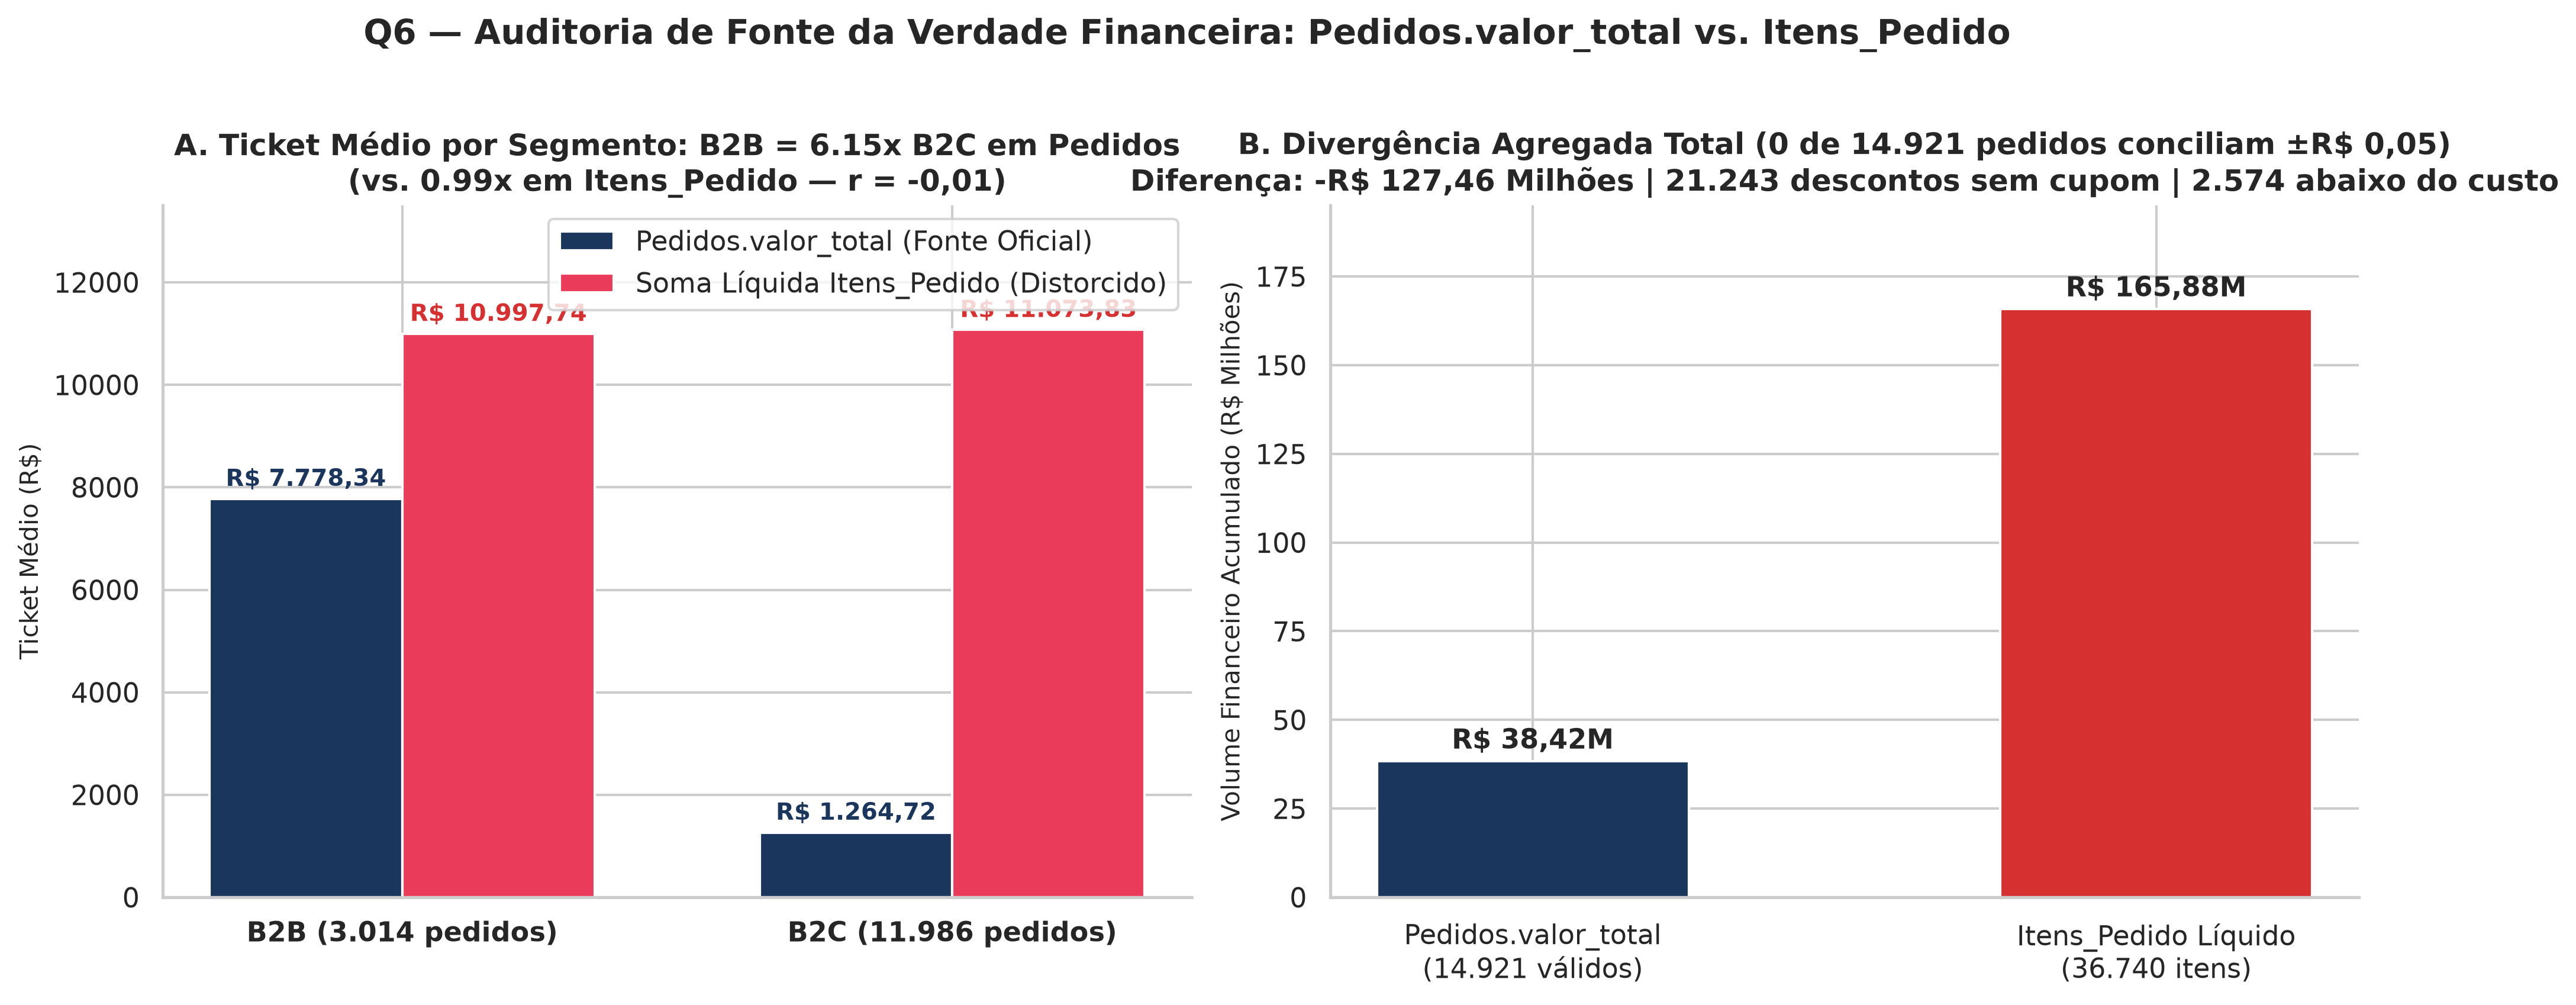

In [3]:
rec, q6_summary = reconcile_orders_vs_items(tables["Pedidos"], itens_full, tables["Clientes"])
seg_df, seg_summary = audit_q6_by_segment(rec, tables["Clientes"])
df_pedidos = build_orders_analytical_df(tables)

print("1) Resumo Global da Reconciliação Pedidos vs. Itens_Pedido (Q6):")
q6_table = pd.DataFrame(
    [
        {"Métrica": "Pedidos Totais / Válidos / Nulos", "Valor": f"{q6_summary['total_pedidos']:,} / {q6_summary['pedidos_validos']:,} / {q6_summary['pedidos_valor_total_nulo']}"},
        {"Métrica": "Pedidos que conciliam (|Pedidos - Itens| <= R$ 0,05)", "Valor": f"{q6_summary['conciliam_liquida']} de {q6_summary['pedidos_validos']:,} (0,00%)"},
        {"Métrica": "Pedidos de 1 único item que conciliam", "Valor": f"{q6_summary['conciliam_1_item']} de {q6_summary['pedidos_1_item']:,} (0,00%)"},
        {"Métrica": "Soma Oficial (Pedidos.valor_total — 14.921 válidos)", "Valor": f"R$ {q6_summary['soma_valor_total_pedidos']:,.2f}"},
        {"Métrica": "Soma Líquida (Itens_Pedido — 15.000 pedidos)", "Valor": f"R$ {q6_summary['soma_liquida_itens']:,.2f}"},
        {"Métrica": "Divergência Agregada (Pedidos - Itens)", "Valor": f"R$ {q6_summary['diferenca_agregada']:,.2f}"},
        {"Métrica": "Ticket Médio / Mediana B2B (Pedidos.valor_total)", "Valor": f"R$ {seg_summary['b2b_media_valor_total']:,.2f} / R$ {seg_summary['b2b_mediana_valor_total']:,.2f}"},
        {"Métrica": "Ticket Médio / Mediana B2C (Pedidos.valor_total)", "Valor": f"R$ {seg_summary['b2c_media_valor_total']:,.2f} / R$ {seg_summary['b2c_mediana_valor_total']:,.2f}"},
        {"Métrica": "Razão B2B / B2C (Pedidos vs. Itens_Pedido)", "Valor": f"{seg_summary['ratio_b2b_b2c']:.2f}x vs. {seg_summary['ratio_itens_b2b_b2c']:.2f}x"},
        {"Métrica": "Receita Total Oficial Imputada (15.000 pedidos)", "Valor": f"R$ {df_pedidos['valor_total_imputado'].sum():,.2f}"},
    ]
)
display(q6_table)
print("\n2) Comparação por Segmento de Cliente (B2B vs. B2C):")
display(seg_df)
display(Image(filename=str(REPO_ROOT / "reports" / "figures" / "q6_reconciliacao_b2b_b2c.png"), width=950))

---
## 3. (Paradoxo C-Level & Q2) Camila (Growth) vs. Rogério (CFO) e Funil de Status

### O Paradoxo entre Growth e Finanças
- **Visão de Camila (Head de Growth):** Enxerga os **15.000 pedidos captados** e a receita bruta total de **R$ 38,42 milhões** (R$ 38,63M imputada), impulsionada por campanhas agressivas de mídia paga (`paid_search`).
- **Visão de Rogério (CFO):** Enxerga a erosão severa entre o pedido captado e o caixa efetivo:
  1. **Cancelamentos estruturalmente elevados (`16,91%` / `2.536` pedidos):** A taxa de cancelamento manteve-se praticamente inalterada entre 2023 (**16,78%**) e 2024 (**17,08%**), drenando **R$ 6.469.713,34** (oficial) antes do faturamento.
  2. **Devoluções (`7,55%` / `1.133` pedidos):** Consomem mais **R$ 3.004.664,16** (oficial) com custo logístico reverso.
  3. **Perda combinada em Não-Convertidos (`cancelado + devolvido`):** **3.669 pedidos (24,46%)** equivalentes a **R$ 9.474.377,50 oficiais** (**R$ 9.520.996,52** imputados).
  4. **Passivo oculto em `em_transito` (`9,14%` / `1.371` pedidos = R$ 3,66M):** Dos 1.371 pedidos com status `em_transito`, **788 são de 2023** (pedidos com mais de 12 meses sem baixa de entrega), indicando falha de atualização de tracking logístico ou extravio não provisionado.

1) Distribuição de Pedidos, Receita Oficial e Ticket Médio por Status (Q2):


,status,qtd_pedidos,receita_pedidos,ticket_medio_pedidos,receita_pedidos_imputada,ticket_medio_imputado,receita_itens_liquida,ticket_medio_itens,pct_pedidos
0,entregue,9959,"25,436,542.40","2,569.09","25,568,291.26","2,567.36","110,840,777.33","11,129.71",66.39
1,cancelado,2537,"6,645,370.22","2,630.79","6,678,825.09","2,632.57","27,954,582.20","11,018.76",16.91
2,em_transito,1371,"3,514,450.94","2,574.69","3,528,531.76","2,573.69","14,944,694.41","10,900.58",9.14
3,devolvido,1133,"2,821,889.09","2,499.46","2,826,910.57","2,495.07","12,138,012.73","10,713.16",7.55



2) Evolução Anual de Cancelamentos e Não-Convertidos (2023 vs. 2024):


,ano,total_pedidos,cancelados,taxa_cancel_pct,nao_convertidos,taxa_nao_conv_pct
0,2023,8386,1407,16.78,2040,24.33
1,2024,6614,1130,17.08,1630,24.64



Resumo de Erosão de Receita: Não-Convertidos = 3,670 pedidos (24.47%) | Receita Perdida Oficial = R$ 9,467,259.31 (Imputada: R$ 9,505,735.66)
Pedidos em_transito de 2023 (zumbis) = 788 vs. 2024 = 583


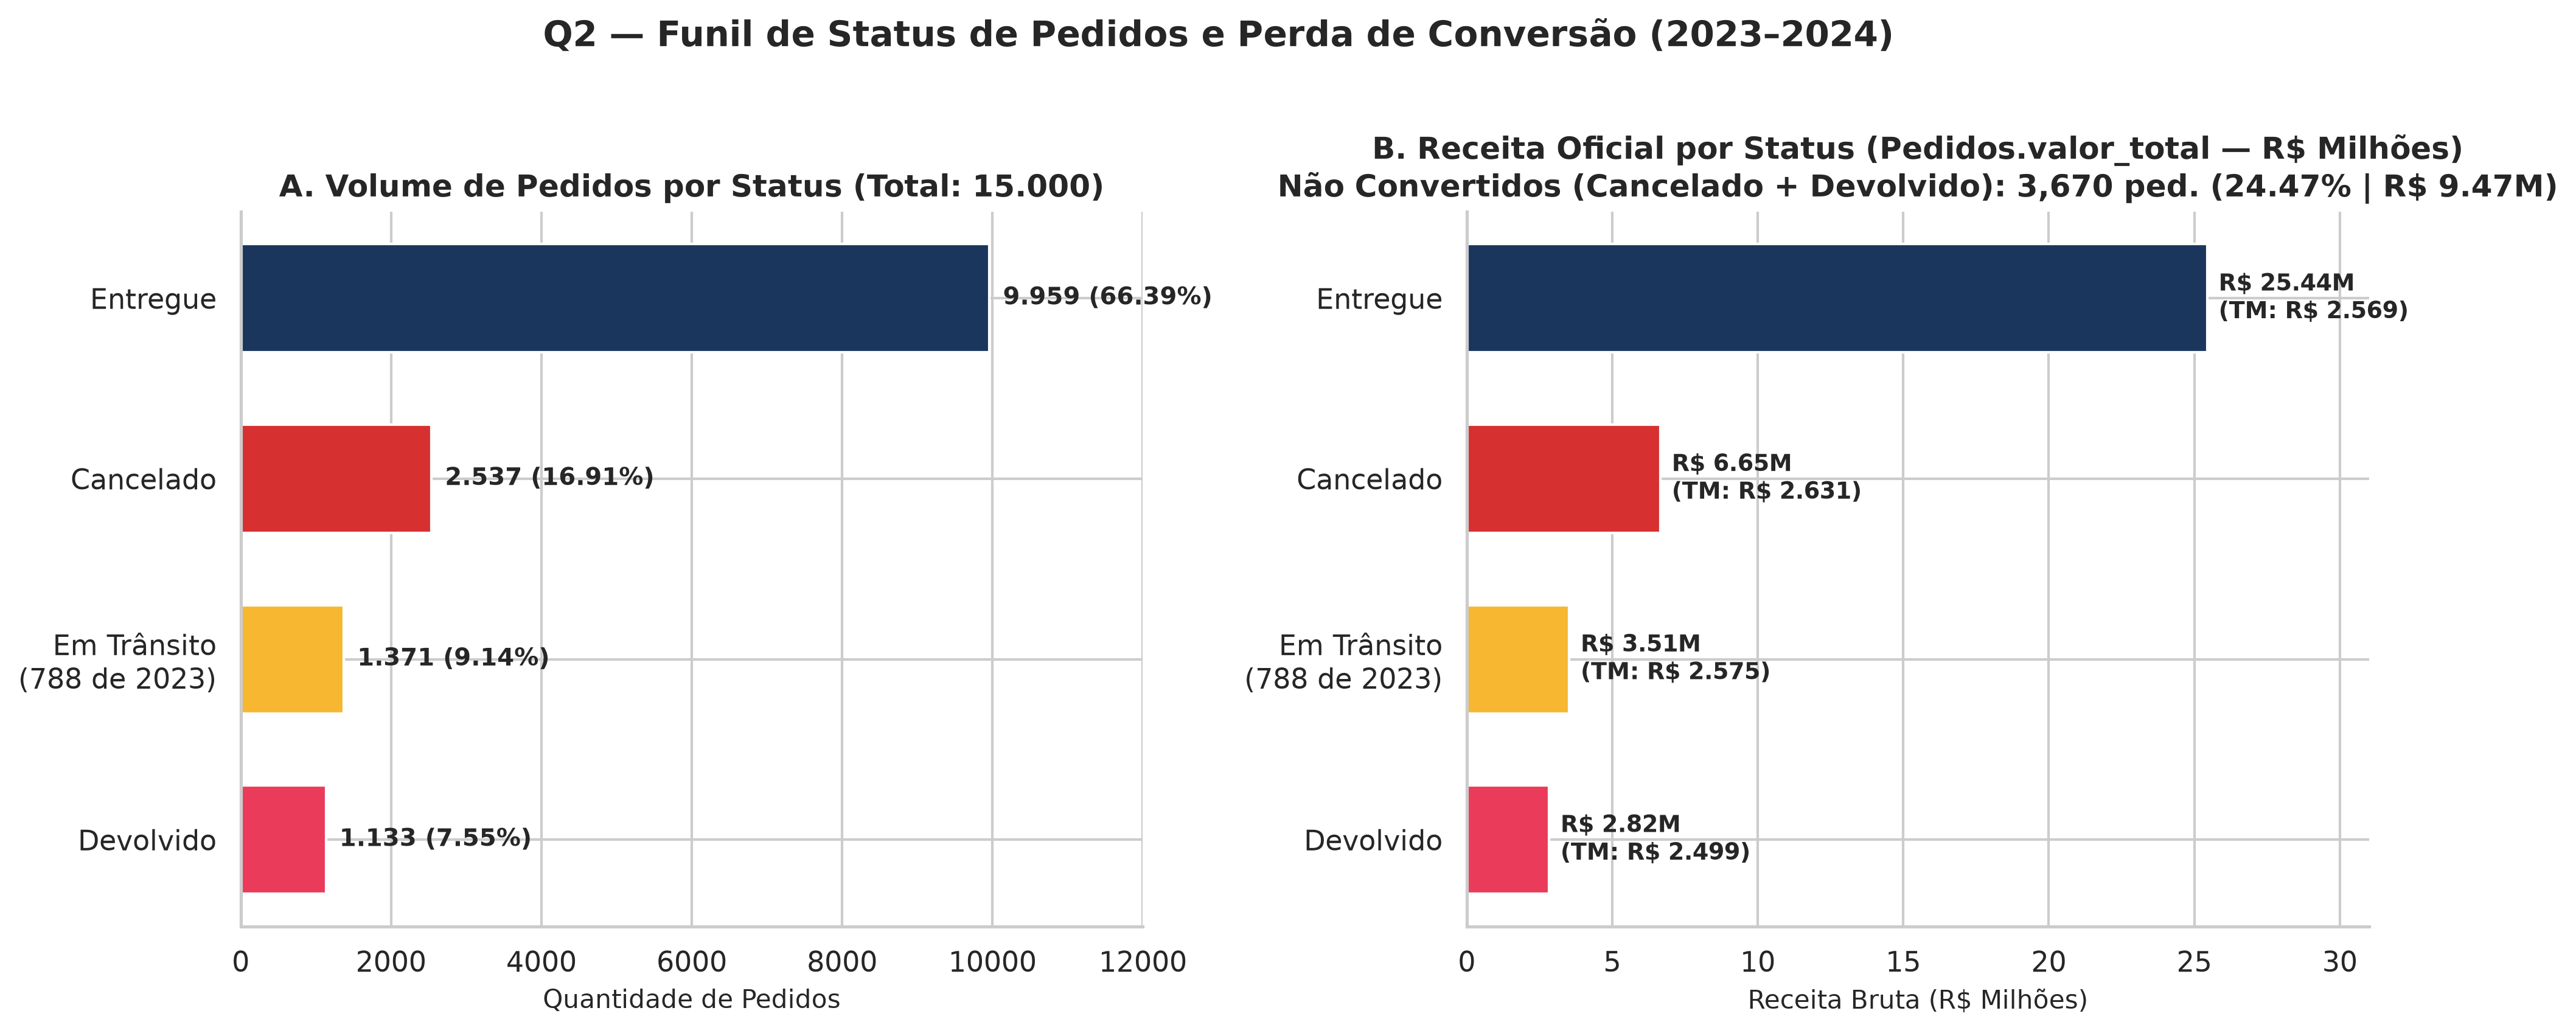

In [4]:
paradox_res = metrics_camila_vs_rogerio(df_pedidos)
q2_df, q2_summary = metrics_q2_status(df_pedidos)

print("1) Distribuição de Pedidos, Receita Oficial e Ticket Médio por Status (Q2):")
display(q2_df)

print("\n2) Evolução Anual de Cancelamentos e Não-Convertidos (2023 vs. 2024):")
display(paradox_res["anual_df"])

print(
    f"\nResumo de Erosão de Receita: "
    f"Não-Convertidos = {q2_summary['nao_convertidos_qtd']:,} pedidos ({q2_summary['nao_convertidos_pct']:.2f}%) | "
    f"Receita Perdida Oficial = R$ {q2_summary['receita_nao_convertida']:,.2f} (Imputada: R$ {q2_summary['receita_nao_convertida_imputada']:,.2f})\n"
    f"Pedidos em_transito de 2023 (zumbis) = {q2_summary['em_transito_2023']} vs. 2024 = {q2_summary['em_transito_2024']}"
)
display(Image(filename=str(REPO_ROOT / "reports" / "figures" / "q2_status_pedidos.png"), width=950))

---
## 4. (Q3) Mix de Categorias: Volume Físico vs. Receita Relativa

Como `Pedidos` não possui chave de categoria e um pedido contém em média 2,45 itens de diferentes categorias, a análise de mix por categoria utiliza `Itens_Pedido` cruzada com `Produtos` — distinguindo rigorosamente **volume físico (`unidades_vendidas`)** de **receita líquida relativa de itens**:
- **Top 3 em Volume Físico (`unidades_vendidas` total = 110.228 unidades):**
  1. `Eletrônicos`: **18.658 unidades** (**1º em volume** | **1º em receita líquida de itens: R$ 26,88M**);
  2. `Casa & Decoração`: **17.899 unidades** (**2º em volume** | **2º em receita líquida de itens: R$ 25,62M**);
  3. `Moda`: **15.680 unidades** (**3º em volume** | **5º em receita líquida de itens: R$ 21,14M**).
- **Por que `Moda` é Top 3 em volume mas cai para 5º em receita?** Os itens de `Moda` tiveram ticket líquido por unidade menor (**R$ 1.347,98**) em comparação a `Beleza & Saúde` (**R$ 1.545,42**, 3º em receita com R$ 22,52M) e `Esporte & Lazer` (**R$ 1.548,74**, 4º em receita com R$ 22,51M).

In [5]:
q3_df = metrics_q3_categories(itens_full, tables["Pedidos"])
print("Ranking das 8 Categorias (Ordenado por Receita Líquida em Itens_Pedido):")
display(q3_df)

Ranking das 8 Categorias (Ordenado por Receita Líquida em Itens_Pedido):


,categoria,unidades_vendidas,linhas_item,receita_liquida,preco_medio_praticado,preco_catalogo_medio,desconto_medio,lucro_total,receita_nao_cancelada,ticket_liquido_por_unidade,margem_pct,rank_receita,rank_volume
0,Eletrônicos,18658,6213,"30,801,235.39","1,750.22","1,876.65",0.07,"10,657,439.67","25,618,685.25","1,650.83",34.60,1,1
1,Casa & Decoração,17899,6008,"24,516,724.17","1,457.30","1,567.41",0.07,"9,602,896.86","20,419,717.76","1,369.73",39.17,2,2
2,Beleza & Saúde,13723,4600,"23,347,196.82","1,811.41","1,942.00",0.07,"7,768,609.90","19,573,137.82","1,701.32",33.27,3,4
3,Esporte & Lazer,12202,4079,"20,233,855.75","1,776.00","1,905.71",0.07,"6,452,180.56","16,957,801.53","1,658.24",31.89,4,5
4,Moda,15680,5191,"19,862,985.25","1,347.98","1,449.33",0.07,"6,837,222.74","16,443,718.20","1,266.77",34.42,5,3
5,Livros & Papelaria,10995,3696,"18,441,544.97","1,792.15","1,923.48",0.07,"6,275,870.75","15,249,558.97","1,677.27",34.03,6,6
6,Bebês & Crianças,10439,3497,"15,254,652.51","1,555.57","1,673.38",0.07,"5,916,850.82","12,659,020.79","1,461.31",38.79,7,8
7,Alimentos & Bebidas,10568,3456,"13,419,871.81","1,356.19","1,461.01",0.07,"4,673,357.01","11,001,844.15","1,269.86",34.82,8,7


---
## 5. (Q4) Auditoria de Canais de Aquisição (`paid_search` vs. Demais Canais)

A estratificação dos 15.000 pedidos pelos 5 canais de aquisição de clientes (`Clientes.canal_aquisicao`) identifica a causa-raiz do problema de cancelamento da OrbitShop:
- **`paid_search` concentra `30,74%` de taxa de cancelamento (`1.219` de `3.965` pedidos):** Embora represente **26,43%** dos pedidos totais, `paid_search` gera **48,07% de todos os cancelamentos da empresa** (`1.219 / 2.536`).
- **Demais 4 canais operam em patamar saudável e homogêneo (`11,69%` a `12,42%`, média `11,93%`):**
  - `orgânico`: **11,69%** (527 / 4.509);
  - `indicação`: **11,76%** (168 / 1.428);
  - `email_marketing`: **11,93%** (257 / 2.155);
  - `redes_sociais`: **12,42%** (365 / 2.943).
- **Significância Estatística Irrefutável:** O teste Qui-quadrado de independência confirma que a anomalia de `paid_search` não é aleatória ($\chi^2 = 734,42, \text{gl} = 4, p = 7,22 \times 10^{-159}$).
- **Ticket Médio Uniforme (~R$ 2.553,51 a R$ 2.616,97):** O ticket médio oficial de `paid_search` (**R$ 2.553,51**) é idêntico ao dos demais canais — logo, `paid_search` não traz clientes de maior valor, apenas destrói conversão líquida.

Desempenho Operacional e Financeiro por Canal de Aquisição (Q4):


,canal_aquisicao,clientes_unicos,pedidos,cancelados,taxa_cancel_pct,nao_convertidos,taxa_nao_conv_pct,ticket_medio_pedidos,ticket_medio_imputado,ticket_medio_itens,pct_b2b
0,paid_search,761,3965,1219,30.74,1471,37.10,"2,553.51","2,555.25","11,137.20",20.23
1,indicação,735,3658,453,12.38,747,20.42,"2,565.98","2,563.47","10,932.04",19.93
2,orgânico,724,3616,426,11.78,730,20.19,"2,521.15","2,517.42","11,157.80",19.19
3,redes_sociais,757,3761,439,11.67,722,19.20,"2,657.17","2,656.43","11,003.20",20.98



Teste Qui-Quadrado (Cancelado vs. Não-Cancelado entre os 5 canais): chi2 = 734.42, gl = 3, p-valor = 7.22e-159
Taxa de Cancelamento paid_search = 30.74% (1219 / 3965) | Ticket Médio Oficial = R$ 2,553.51


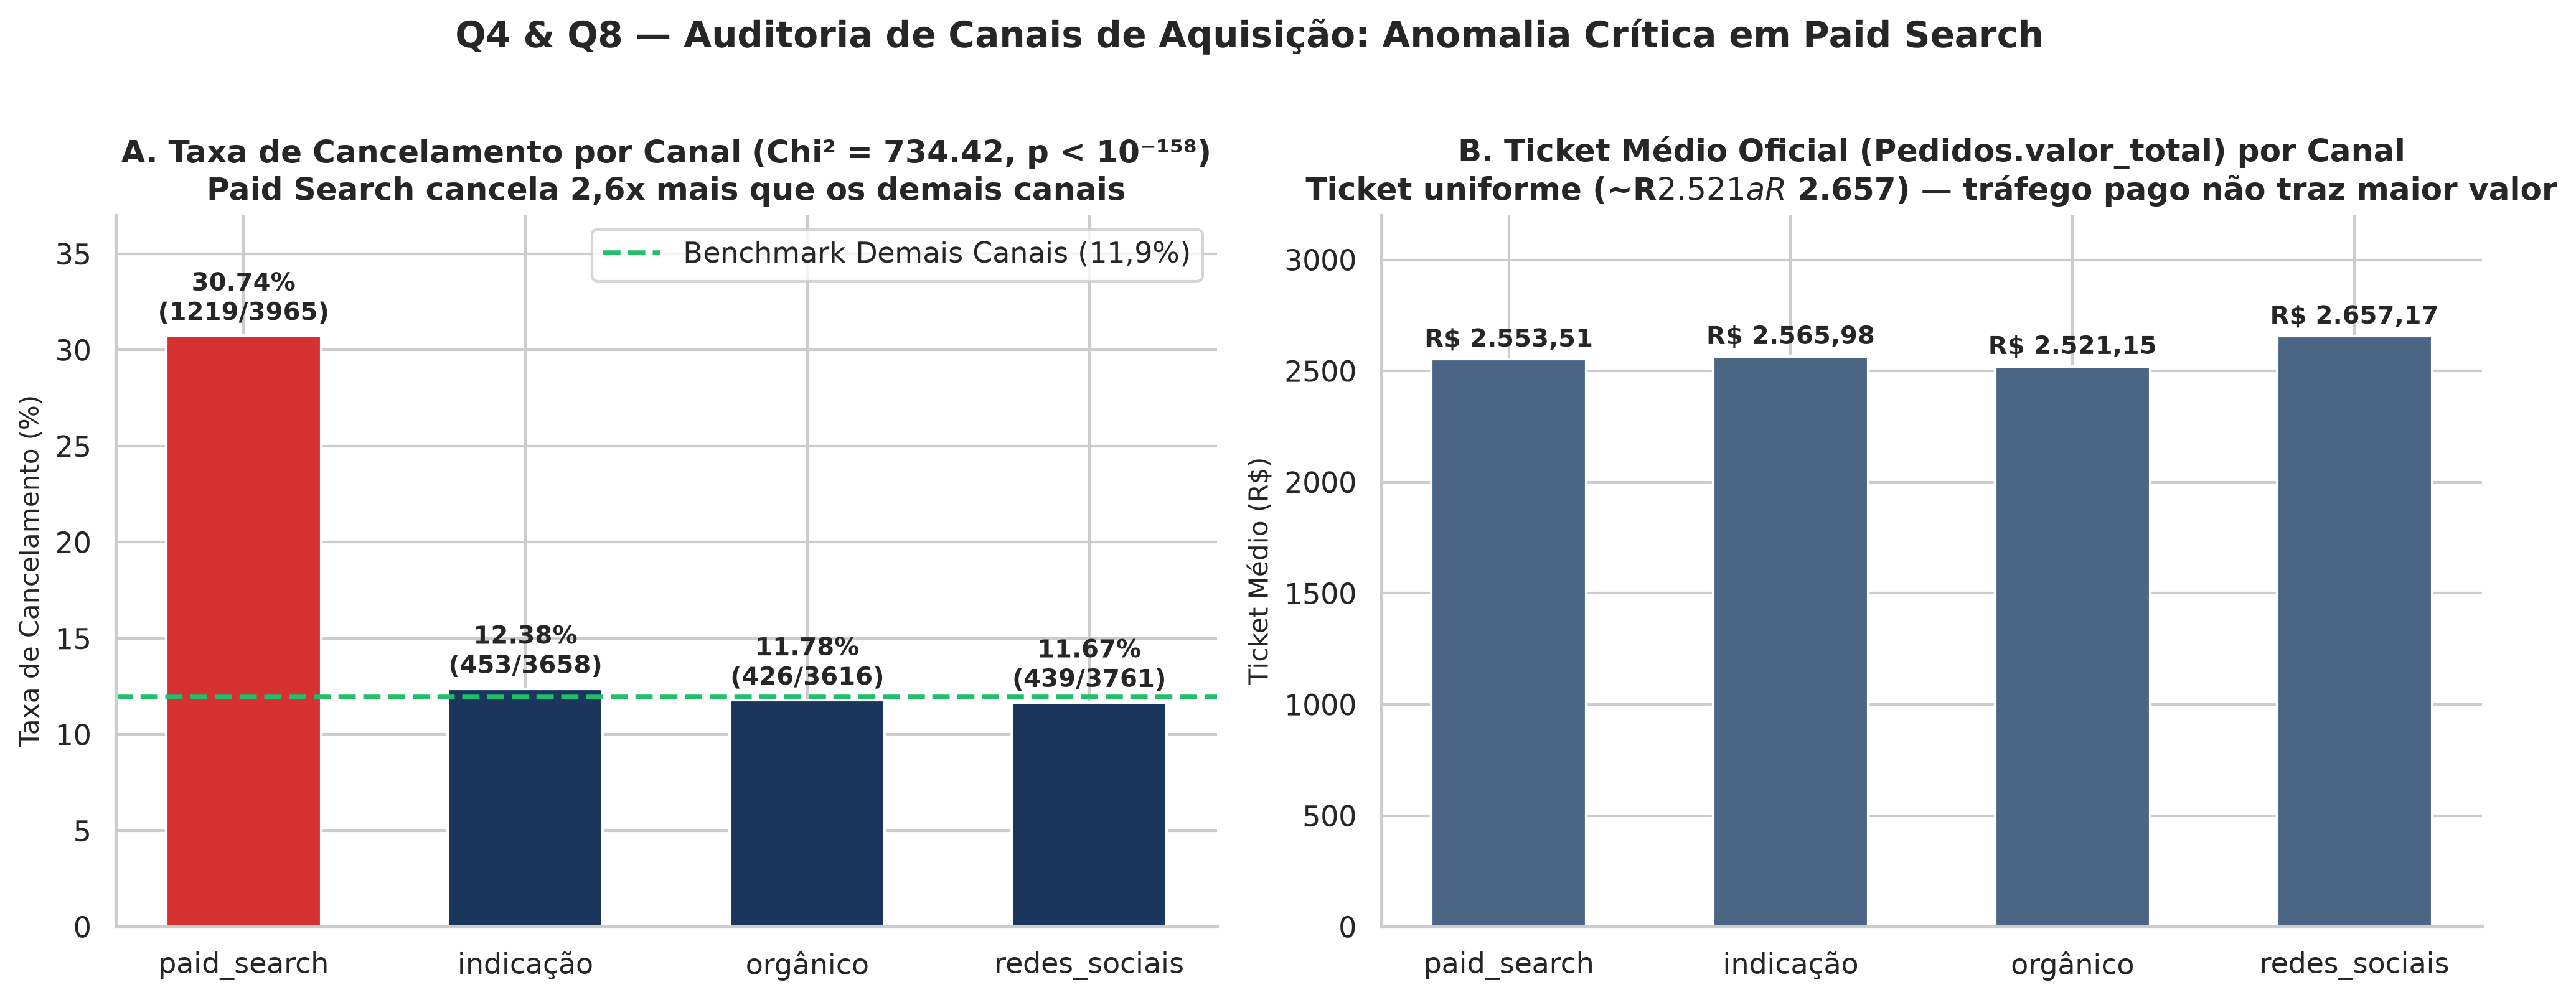

In [6]:
q4_df, q4_test = metrics_q4_channels(df_pedidos)
print("Desempenho Operacional e Financeiro por Canal de Aquisição (Q4):")
display(q4_df)

print(
    f"\nTeste Qui-Quadrado (Cancelado vs. Não-Cancelado entre os 5 canais): "
    f"chi2 = {q4_test['chi2']:.2f}, gl = {q4_test['dof']}, p-valor = {q4_test['p_value']:.2e}\n"
    f"Taxa de Cancelamento paid_search = {q4_test['paid_search_taxa_cancel_pct']:.2f}% "
    f"({q4_test['paid_search_cancelados']} / {q4_test['paid_search_pedidos']}) | "
    f"Ticket Médio Oficial = R$ {q4_test['paid_search_ticket_medio']:,.2f}"
)
display(Image(filename=str(REPO_ROOT / "reports" / "figures" / "q4_cancelamento_canais.png"), width=950))

---
## 6. (Q5) Evolução Mensal 2023–2024 e Anomalia de Novembro/2023

A série histórica mensal dos 24 meses (jan/2023 a dez/2024) desmonta a narrativa de crescimento orgânico contínuo e expõe dois fatos críticos para o valuation da Series C:
1. **Estagnação Basal em ~551 pedidos/mês:** Excluindo novembro/2023, a OrbitShop operou de forma estacionária ao longo de 23 meses com média de **551,43 pedidos/mês** (oscilando numa faixa estreita entre 505 e 599 pedidos/mês).
2. **Pico Isolado em Novembro/2023 (`2.317` pedidos = `4,20x` a média mensal):**
   - O salto ocorreu de forma perfeitamente simétrica nos 3 canais de venda: `app` (**783**), `site` (**770**) e `marketplace` (**764**);
   - **Não repetição em Novembro/2024 (`585` pedidos, `-74,75%` YoY):** Em novembro/2024, o volume retornou ao patamar basal (585 pedidos), explicando a queda aparente do volume anual de 2023 (**8.431 pedidos**) para 2024 (**6.569 pedidos**).

Resumo da Anomalia Sazonal (Q5):


,Valor
pico_ano_mes,2023-11
pedidos_nov_2023,2317
ped_site_nov_2023,770
ped_app_nov_2023,783
ped_mkt_nov_2023,764
pedidos_nov_2024,585
media_pedidos_ex_nov2023,551.43
multiplo_pico_vs_media,4.20



Recorte Comparativo: Out–Dez 2023 vs. Out–Dez 2024:


,ano_mes,total_pedidos,cancelados,taxa_cancel_pct,pct_com_cupom,receita_pedidos,receita_pedidos_imputada,receita_liquida,ped_site,ped_app,ped_mkt
0,2023-10,554,95,17.15,33.39,"1,298,732.48","1,312,813.30","6,306,256.40",197,190,167
1,2023-11,2317,403,17.39,34.44,"5,837,238.49","5,847,281.45","25,672,195.15",770,783,764
2,2023-12,558,85,15.23,38.35,"1,452,456.79","1,456,222.90","5,900,691.71",183,167,208
3,2024-10,545,100,18.35,31.93,"1,281,621.20","1,291,664.16","5,946,709.14",171,177,197
4,2024-11,585,94,16.07,31.97,"1,564,775.93","1,566,031.30","6,511,188.27",191,201,193
5,2024-12,520,78,15.00,33.65,"1,500,577.46","1,503,088.20","5,559,465.34",174,176,170


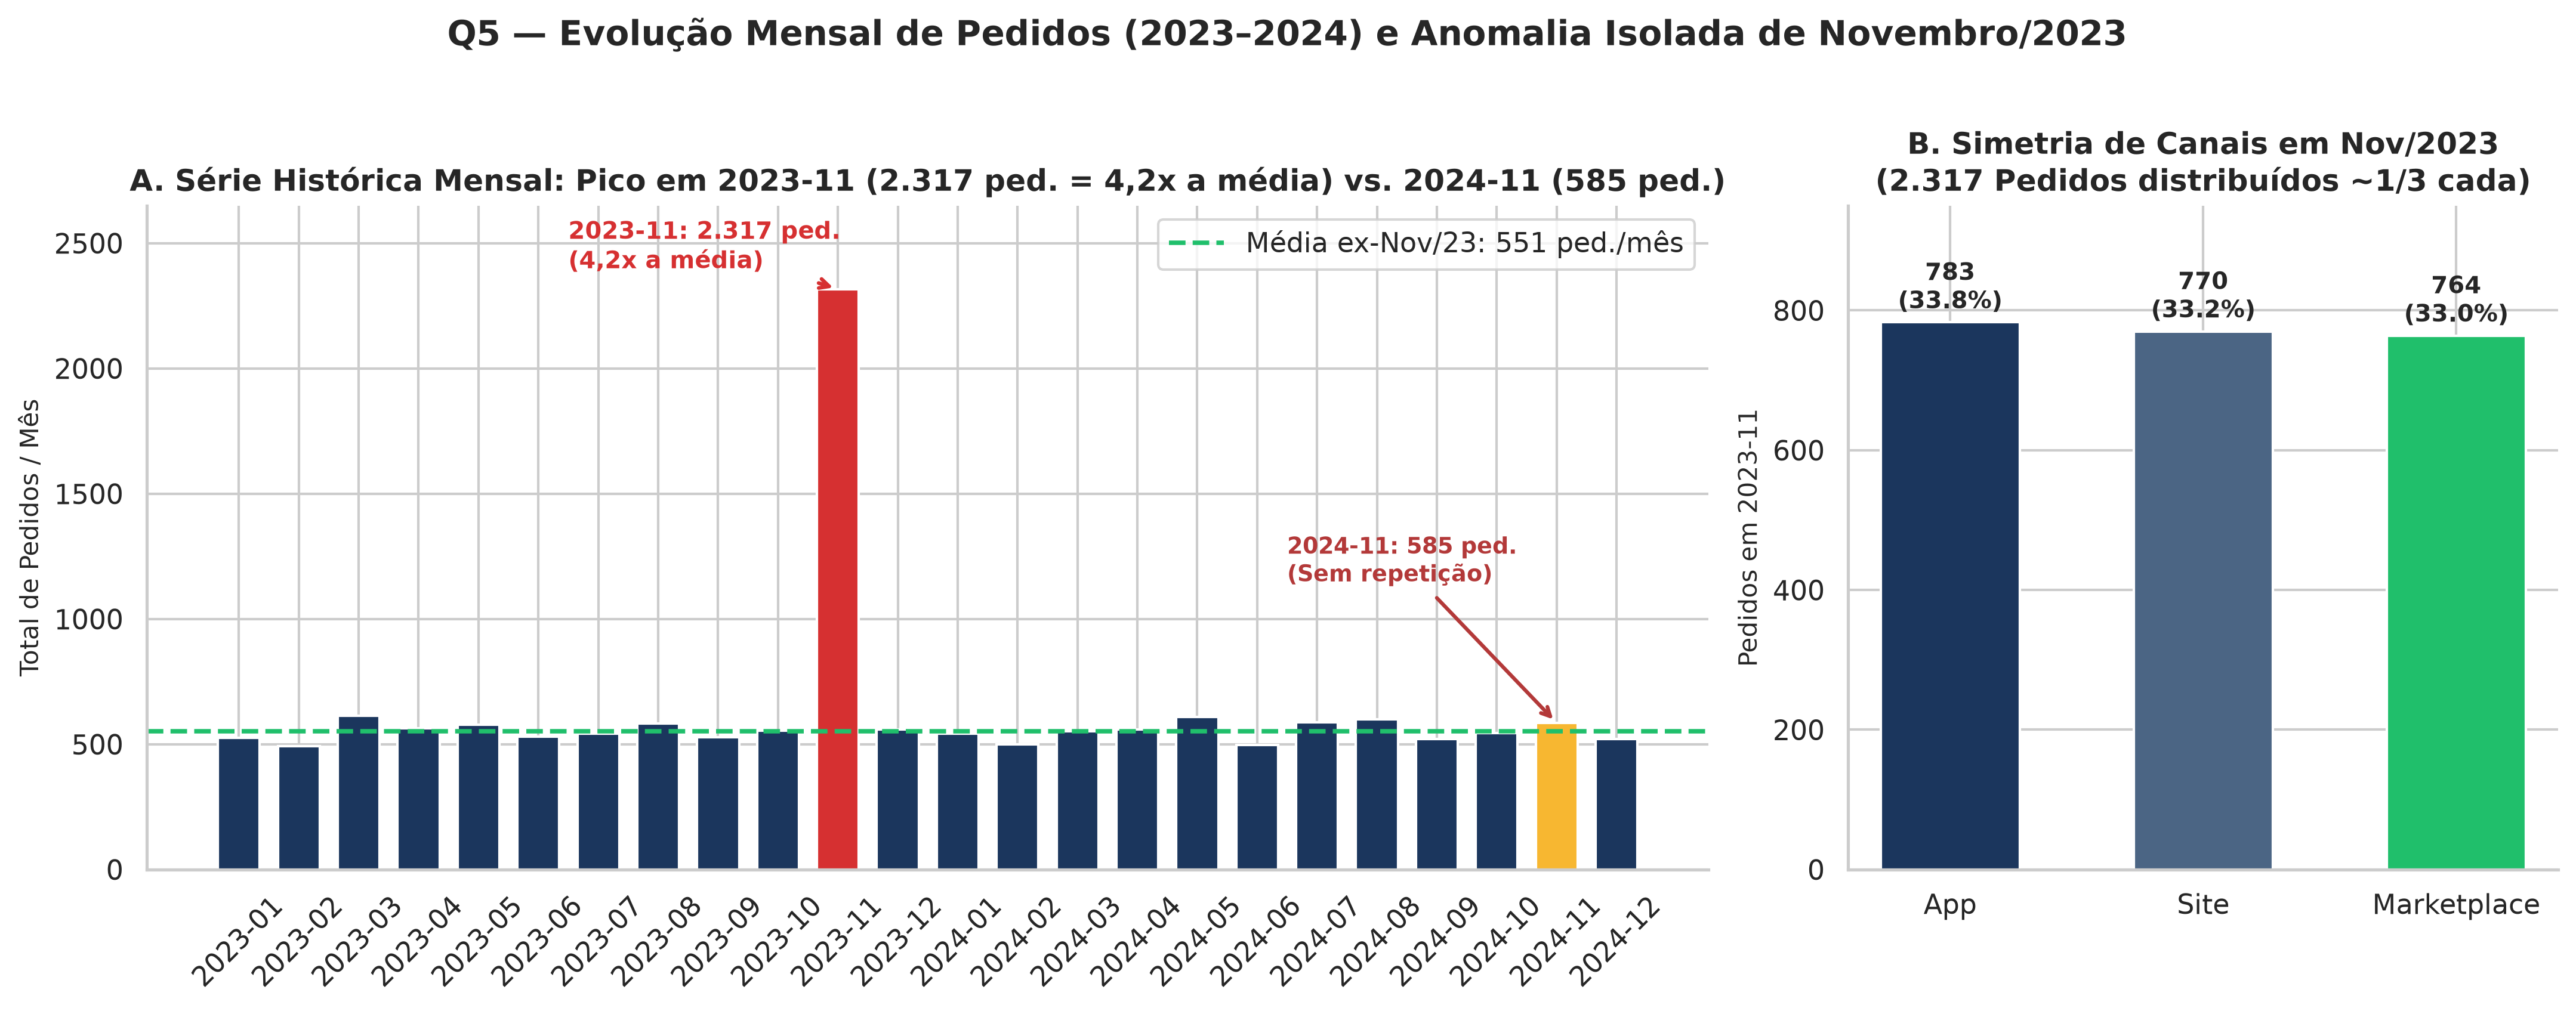

In [7]:
q5_df, q5_summary = metrics_q5_monthly(df_pedidos)
print("Resumo da Anomalia Sazonal (Q5):")
display(pd.DataFrame([q5_summary]).T.rename(columns={0: "Valor"}))

print("\nRecorte Comparativo: Out–Dez 2023 vs. Out–Dez 2024:")
comp_months = q5_df[q5_df["ano_mes"].isin(["2023-10", "2023-11", "2023-12", "2024-10", "2024-11", "2024-12"])]
display(comp_months.reset_index(drop=True))
display(Image(filename=str(REPO_ROOT / "reports" / "figures" / "q5_serie_mensal_2023_2024.png"), width=950))

---
## 7. (Q7) Qualidade de Fornecedores vs. Operação de Suporte

Cruzando `Produtos`, `Itens_Pedido`, `Avaliacoes` (`8.000` registros) e `Tickets_Suporte` (`4.000` registros), separamos claramente **defeito de produto (fornecedor)** de **gargalo operacional de atendimento/logística**:
1. **`DeltaFornece ME` é o único fornecedor problemático em qualidade de produto:**
   - Apresenta nota média de avaliação de **2,30** e **59,90% de avaliações críticas (notas 1 e 2)** em 808 avaliações;
   - Todos os outros 8 fornecedores formam um cluster homogêneo com nota média entre **3,62 e 3,84** e apenas **20,56% a 24,52%** de notas 1–2.
2. **Volume de Tickets de Suporte é sistêmico e NÃO é puxado por `DeltaFornece ME`:**
   - A incidência de chamados normalizada pelo volume de itens vendidos varia de **22,16 a 24,85 tickets por 100 itens** entre todos os 9 fornecedores (`DeltaFornece ME` = **22,94 tickets/100 itens**, 6º entre 9);
   - O pico de tickets em **novembro/2023 (375 tickets)** e **dezembro/2023 (391 tickets)** — vs. média basal de **153 tickets/mês** — atingiu todos os 9 fornecedores simultaneamente em razão do colapso logístico pós-Black Friday 2023.

Matriz de Qualidade de Produto (Avaliações) vs. Incidência de Suporte (Tickets/100 Itens) por Fornecedor (Q7):


,fornecedor,itens_vendidos,unidades,receita_liquida,taxa_itens_cancelados_pct,qtd_avaliacoes,nota_media,pct_notas_baixas_1_2,tickets_associados,tickets_defeito_troca,tickets_por_100_itens
0,DeltaFornece ME,4390,13023,"18,421,134.82",16.95,985,2.30,59.90,1007,194,22.94
1,SulFornece SA,4098,12241,"16,340,237.77",18.18,845,3.62,22.37,956,176,23.33
2,NorteImport Ltda,3893,11742,"16,261,722.79",17.57,824,3.66,22.09,928,175,23.84
3,TechBrasil Ltda,4890,14625,"24,861,973.14",17.24,1027,3.74,20.25,1191,240,24.36
4,AlphaSupply,3098,9410,"12,588,798.88",17.46,684,3.80,18.13,770,139,24.85
5,GlobalBR Comércio,3994,12018,"18,246,046.84",17.33,912,3.80,17.43,964,181,24.14
6,FornecedorX,3568,10715,"20,006,833.78",17.04,789,3.81,18.76,883,178,24.75
7,MegaDistribuidora,5493,16403,"25,768,891.85",16.46,1241,3.82,17.73,1217,228,22.16
8,MarcoPolo Distribuição,3316,9987,"13,382,426.80",16.19,693,3.84,17.75,807,154,24.34



Síntese Comparativa (Q7): Outlier = DeltaFornece ME (Nota Média = 2.30, Notas 1-2 = 59.90%, Tickets/100 itens = 22.94) | Pares (8 fornecedores): Nota Média = 3.62–3.84, Tickets/100 itens = 22.16–24.85 | Pico Tickets: Nov/23 = 375, Dez/23 = 391


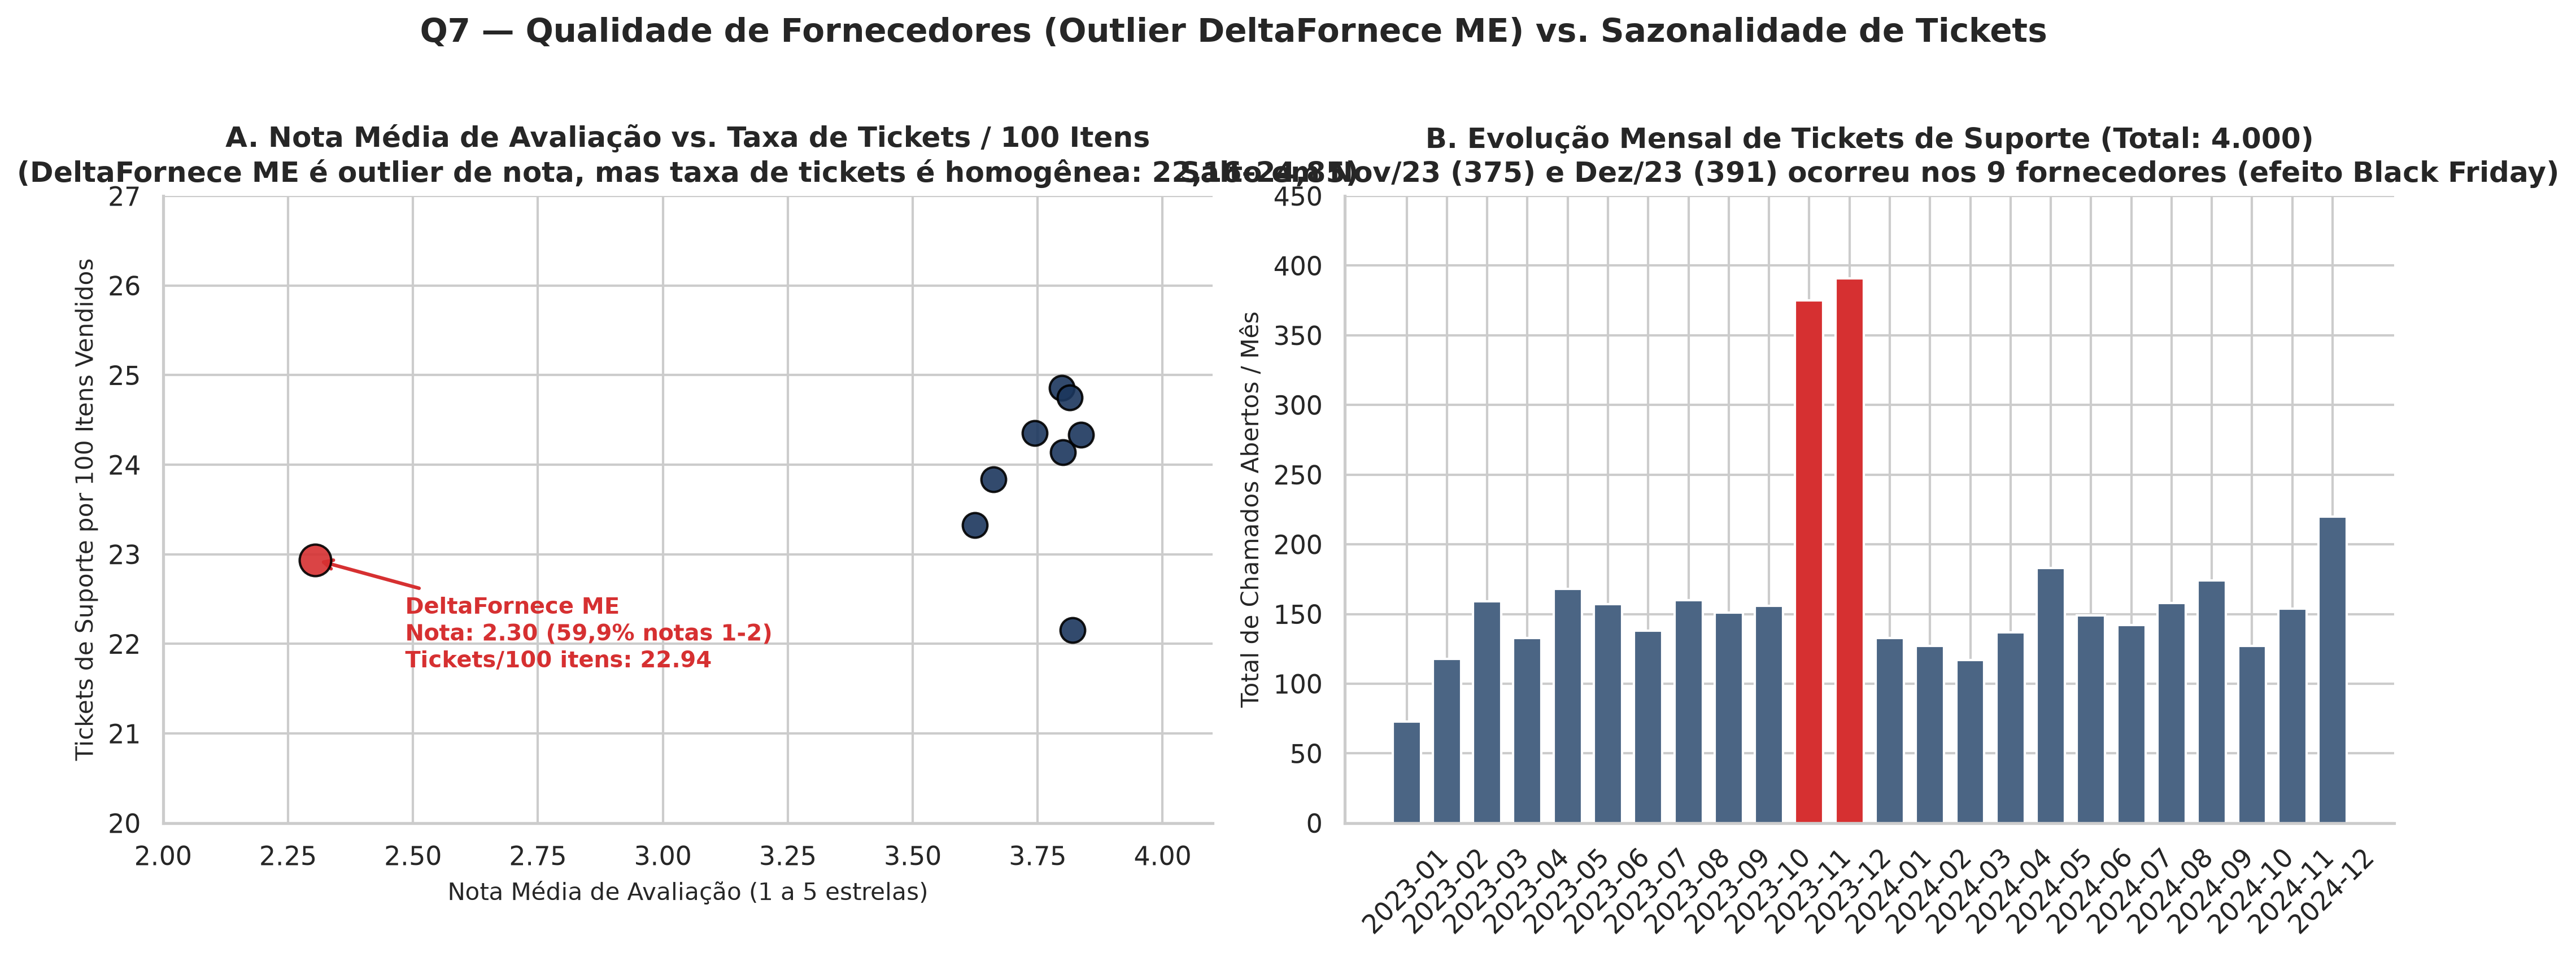

In [8]:
q7_forn, tickets_mensal, q7_summary = metrics_q7_suppliers(tables, itens_full)
print("Matriz de Qualidade de Produto (Avaliações) vs. Incidência de Suporte (Tickets/100 Itens) por Fornecedor (Q7):")
display(q7_forn)

print(
    f"\nSíntese Comparativa (Q7): "
    f"Outlier = {q7_summary['outlier_fornecedor']} (Nota Média = {q7_summary['delta_nota_media']:.2f}, "
    f"Notas 1-2 = {q7_summary['delta_pct_notas_1_2']:.2f}%, Tickets/100 itens = {q7_summary['delta_tickets_por_100_itens']:.2f}) | "
    f"Pares (8 fornecedores): Nota Média = {q7_summary['peers_min_nota_media']:.2f}–{q7_summary['peers_max_nota_media']:.2f}, "
    f"Tickets/100 itens = {q7_summary['peers_min_tickets_por_100_itens']:.2f}–{q7_summary['peers_max_tickets_por_100_itens']:.2f} | "
    f"Pico Tickets: Nov/23 = {q7_summary['tickets_nov_2023']}, Dez/23 = {q7_summary['tickets_dez_2023']}"
)
display(Image(filename=str(REPO_ROOT / "reports" / "figures" / "q7_fornecedores_qualidade_tickets.png"), width=950))

---
## 8. (Q8 & Q9) Recomendação Prioritária Única e Governança para o Board

### 8.1 (Q8) Recomendação Prioritária Única: Reestruturação Imediata do Funil `paid_search`
Se a liderança da OrbitShop puder executar **uma única ação prioritária nos próximos 90 dias** antes do fechamento da rodada Series C, deve **auditar e reestruturar a aquisição e o checkout do canal `paid_search`**:
- **Por que esta é a alavanca #1:** `paid_search` responde por **48,07% de todos os cancelamentos da empresa** (`1.219 / 2.536`), com taxa de cancelamento de **30,74%** contra **11,93%** nos outros 4 canais (~11,9%).
- **Impacto Financeiro Direto e Auditável:**
  - Convergir a taxa de cancelamento de `paid_search` de **30,74%** para o benchmark dos demais canais (**11,9%**) preserva **~747 pedidos** já adquiridos;
  - Ao ticket médio oficial do canal (**R$ 2.553,51**), isso representa a recuperação direta de **R$ 1.907.826,64 (~R$ 1,91 milhão)** em receita bruta, reduzindo o cancelamento global da OrbitShop de **16,91% para ~11,9%** sem gastar R$ 1 adicional em mídia.

### 8.2 (Q9) Ações Complementares de Governança (Plano 90 Dias)
1. **Saneamento do Pipeline de Dados (TI/Engenharia):** Bloquear o uso de `Itens_Pedido` para apuração de receita/margem no Data Warehouse, corrigir a rotina ETL que sobrescreve `preco_praticado` (~R$ 1.501) e gera descontos sem cupom (57,82%), e tornar `Pedidos.valor_total` (`NOT NULL`) obrigatório no banco transacional.
2. **Auditoria de Qualidade / SLA Comercial com `DeltaFornece ME` (Compras):** Notificar `DeltaFornece ME` (nota **2,30**, **59,90%** de notas 1–2) com plano de substituição/homologação de lotes dos SKUs fornecidos.
3. **Baixa Contábil e Logística de Pedidos Presos (Operações/CFO):** Auditar e baixar os **788 pedidos de 2023 que permanecem com status `em_transito`**, limpando o balanço para a auditoria externa da Series C.

In [9]:
q8_rec = metrics_q8_recommendation(df_pedidos)
q8_table = pd.DataFrame(
    [
        {"Indicador (Alavanca #1 — paid_search)": "Volume Total do Canal paid_search", "Valor": f"{q8_rec['pedidos_paid_search']:,} pedidos (26,43% da base)"},
        {"Indicador (Alavanca #1 — paid_search)": "Cancelamentos Atuais em paid_search", "Valor": f"{q8_rec['cancelados_paid_search']:,} pedidos ({q8_rec['taxa_paid_search_pct']:.2f}%)"},
        {"Indicador (Alavanca #1 — paid_search)": "Benchmark (Taxa Média dos Demais 4 Canais)", "Valor": f"{q8_rec['taxa_benchmark_prd_pct']:.2f}% (exato: {q8_rec['taxa_benchmark_outros_canais_pct']:.2f}%)"},
        {"Indicador (Alavanca #1 — paid_search)": "Pedidos Recuperados no Cenário Benchmark", "Valor": f"{q8_rec['pedidos_recuperados']:.1f} (~{round(q8_rec['pedidos_recuperados'])} pedidos)"},
        {"Indicador (Alavanca #1 — paid_search)": "Ticket Médio Oficial do Canal paid_search", "Valor": f"R$ {q8_rec['ticket_medio_paid_search']:,.2f}"},
        {"Indicador (Alavanca #1 — paid_search)": "Receita Bruta Recuperada Estimada", "Valor": f"R$ {q8_rec['receita_bruta_recuperavel']:,.2f} (~R$ 1,91M)"},
    ]
)
display(q8_table)

,Indicador (Alavanca #1 — paid_search),Valor
0,Volume Total do Canal paid_search,"3,965 pedidos (26,43% da base)"
1,Cancelamentos Atuais em paid_search,"1,219 pedidos (30.74%)"
2,Benchmark (Taxa Média dos Demais 4 Canais),11.90% (exato: 11.94%)
3,Pedidos Recuperados no Cenário Benchmark,747.2 (~747 pedidos)
4,Ticket Médio Oficial do Canal paid_search,"R$ 2,553.51"
5,Receita Bruta Recuperada Estimada,"R$ 1,907,895.65 (~R$ 1,91M)"
